![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Ensemble Methods
*Data Science & Machine Learning - Week 5, Day 2*

## How to use this notebook

On Week 4 Day 5 a single decision tree was the best model for predicting which phone customers leave, and yesterday tuning it raised its test F1 to 0.853. Today you combine many trees into one model, an **ensemble**, and see how far that takes the same problem.

There are two families. **Bagging** and **random forests** train many trees independently and average them, which makes the prediction more stable. **Boosting** trains trees one after another, each one correcting the mistakes of the previous ones. Gradient boosting in particular is what wins most competitions on tabular data.

The slides **2. Ensemble methods** in this folder go with the notebook. The churn data, `churn.csv`, is in this folder too, so download or clone the whole `s-503` folder. Run the cells in order.

## Table of contents

- [Setup](#Setup)
- [1. Why combine models?](#1.-Why-combine-models?)
- [2. One tree is unstable](#2.-One-tree-is-unstable)
    - [A picture in two dimensions](#A-picture-in-two-dimensions)
    - [The same instability on churn](#The-same-instability-on-churn)
- [3. Bagging](#3.-Bagging)
    - [What a bootstrap sample looks like](#What-a-bootstrap-sample-looks-like)
    - [BaggingClassifier](#BaggingClassifier)
- [4. Random forests](#4.-Random-forests)
    - [How many trees?](#How-many-trees?)
    - [A forest is more stable than a tree](#A-forest-is-more-stable-than-a-tree)
- [5. Feature importance](#5.-Feature-importance)
    - [Impurity-based importance](#Impurity-based-importance)
    - [Permutation importance](#Permutation-importance)
- [6. Boosting](#6.-Boosting)
    - [AdaBoost](#AdaBoost)
    - [Gradient boosting](#Gradient-boosting)
    - [HistGradientBoosting: the one to use in practice](#HistGradientBoosting:-the-one-to-use-in-practice)
- [7. Comparing everything on churn](#7.-Comparing-everything-on-churn)
- [Summary](#Summary)
- [Appendix](#Appendix)
    - [A.1 Ensembles for regression](#A.1-Ensembles-for-regression)
    - [A.2 Voting and stacking](#A.2-Voting-and-stacking)
    - [A.3 Multiclass problems and error-correcting output codes](#A.3-Multiclass-problems-and-error-correcting-output-codes)
    - [A.4 Bagging by hand](#A.4-Bagging-by-hand)

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

from sklearn.datasets import make_moons, load_diabetes, load_digits
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestRegressor, HistGradientBoostingRegressor,
                              VotingClassifier, StackingClassifier)
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier, OutputCodeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, log_loss

## 1. Why combine models?

Before a major operation you ask a second doctor; before buying something you read several reviews. An ensemble does the same: it trains several models and lets them vote.

Voting only helps if the models **make different mistakes**. Suppose each of 25 classifiers is right 65% of the time, and their errors are independent. The majority is wrong only when 13 or more of them are wrong at once, which the binomial distribution from Week 4 tells us is rare:

In [2]:
for n_models in [1, 5, 25, 101]:
    majority = n_models // 2 + 1
    p_majority_right = 1 - binom.cdf(majority - 1, n_models, 0.65)
    print(f"{n_models:>3} models, each 65% right: the majority vote is right {p_majority_right:.1%} of the time")

  1 models, each 65% right: the majority vote is right 65.0% of the time
  5 models, each 65% right: the majority vote is right 76.5% of the time
 25 models, each 65% right: the majority vote is right 94.0% of the time
101 models, each 65% right: the majority vote is right 99.9% of the time


In practice the models are trained on the same data, so their errors are never fully independent and the gain is smaller. The whole art of ensembles is to create **diversity**, models that disagree in useful ways:

+ **Different training data**: each model sees a different random sample of the rows (bagging).
+ **Different features**: each model, or each split, sees a random subset of the columns (random forests).
+ **Different focus**: each new model concentrates on the cases the previous ones got wrong (boosting).
+ **Different algorithms**: a tree, a logistic regression and a KNN vote together (voting and stacking, in the appendix).

## 2. One tree is unstable

Decision trees are the usual building block, because a deep tree has low bias (it can fit almost anything) but **high variance**: small changes in the training data produce a very different tree.

### A picture in two dimensions

The two-moons dataset has two classes that curl around each other, with noise. An unrestricted tree carves a box around almost every training point.

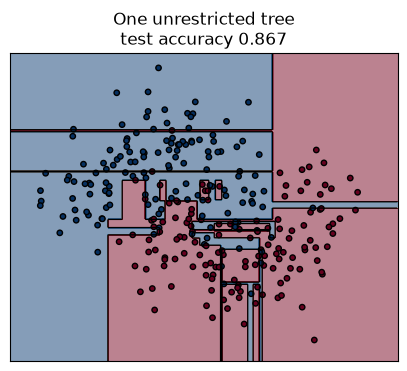

In [3]:
X_m, y_m = make_moons(n_samples=400, noise=0.35, random_state=0)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.3, random_state=0)

xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]

def plot_boundary(model, ax, title):
    zz = model.predict_proba(grid_points)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.5)
    ax.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=1)
    ax.scatter(Xm_train[:, 0], Xm_train[:, 1], c=ym_train, cmap="RdBu_r", edgecolor="k", s=15)
    test_acc = model.score(Xm_test, ym_test)
    ax.set_title(f"{title}\ntest accuracy {test_acc:.3f}")
    ax.set_xticks([]); ax.set_yticks([])

tree_m = DecisionTreeClassifier(random_state=0).fit(Xm_train, ym_train)
fig, ax = plt.subplots(figsize=(5, 4))
plot_boundary(tree_m, ax, "One unrestricted tree")
plt.show()

The black line is the decision boundary. The islands of red inside the blue region, and the other way round, are the tree memorising noise.

### The same instability on churn

Now the churn data, prepared and split exactly as on Week 4 Day 5 and yesterday.

In [4]:
churn = pd.read_csv("churn.csv")
y = (churn["Churn?"] == "True.").astype(int)
X = churn.drop(columns=["State", "Phone", "Churn?"])
for col in ["Int'l Plan", "VMail Plan"]:
    X[col] = (X[col] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(len(X_train), "training rows,", len(X_test), "test rows, churn share", round(y.mean(), 3))

2499 training rows, 834 test rows, churn share 0.145


To see the variance, train a tree on ten slightly different versions of the training set. Each version is drawn at random **with replacement** from the training rows (more on that in the next section), so the ten sets mostly overlap. A stable model would score about the same every time.

In [5]:
rng = np.random.default_rng(0)
resamples = [rng.integers(0, len(X_train), len(X_train)) for _ in range(10)]

tree_f1 = []
for idx in resamples:
    tree = DecisionTreeClassifier(random_state=0).fit(X_train.iloc[idx], y_train.iloc[idx])
    tree_f1.append(f1_score(y_test, tree.predict(X_test)))
print("Test F1 of 10 trees:", np.round(tree_f1, 3))
print(f"from {min(tree_f1):.3f} to {max(tree_f1):.3f}, standard deviation {np.std(tree_f1):.3f}")

Test F1 of 10 trees: [0.781 0.72  0.767 0.763 0.713 0.712 0.693 0.743 0.71  0.751]
from 0.693 to 0.781, standard deviation 0.028


Same algorithm, almost the same data, and the score jumps around by almost 0.1. Averaging many such trees cancels out much of that noise, which is the idea behind bagging.

## 3. Bagging

**Bagging** (*bootstrap aggregating*) has two steps:

1. Draw many **bootstrap samples** of the training set: as many rows as the original, drawn at random *with replacement*. Each sample repeats some rows and leaves others out.
2. Train one model on each sample, then combine them: a majority vote (or the average probability) for classification, the average for regression.

### What a bootstrap sample looks like

In [6]:
idx = resamples[0]
unique_share = len(np.unique(idx)) / len(X_train)
print(f"Rows in the sample: {len(idx)}")
print(f"Different original rows in it: {len(np.unique(idx))} ({unique_share:.1%})")
print("Most repeated row appears", np.bincount(idx).max(), "times")

Rows in the sample: 2499
Different original rows in it: 1571 (62.9%)
Most repeated row appears 6 times


A bootstrap sample contains about **63%** of the original rows; the rest are copies. The rows left out of a sample, about 37%, are called **out-of-bag** rows. They act as a free validation set for the model trained on that sample, which section 4 uses.

### BaggingClassifier

scikit-learn does all of this for you. `estimator` is the model to repeat, and `n_estimators` how many copies to train.

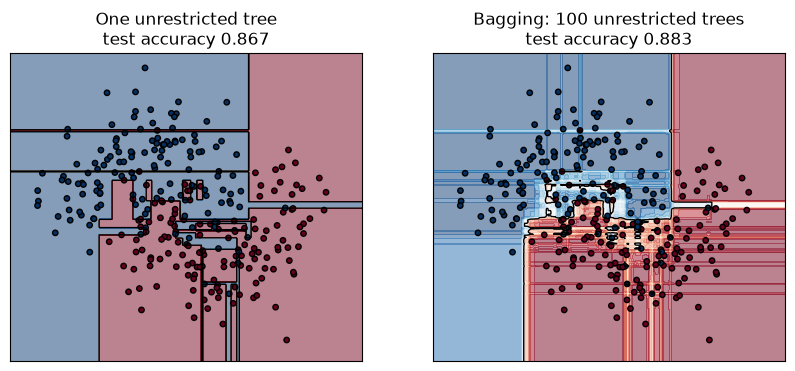

In [7]:
bagging_m = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0).fit(Xm_train, ym_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_boundary(tree_m, axes[0], "One unrestricted tree")
plot_boundary(bagging_m, axes[1], "Bagging: 100 unrestricted trees")
plt.show()

Every tree in the bag is just as unrestricted as the one on the left, but their individual quirks average out, and test accuracy rises from 0.867 to 0.883. The boundary is smoother, and the shading shows a probability, the share of trees voting for each class, rather than hard boxes.

On churn:

In [8]:
def report(name, model):
    y_pred = model.predict(X_test)
    print(f"{name:<26} accuracy {accuracy_score(y_test, y_pred):.3f}   F1 {f1_score(y_test, y_pred):.3f}   "
          f"recall {recall_score(y_test, y_pred):.3f}   precision {precision_score(y_test, y_pred):.3f}")

tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
bagging = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0, n_jobs=-1).fit(X_train, y_train)
report("One unrestricted tree", tree)
report("Bagging, 100 trees", bagging)

One unrestricted tree      accuracy 0.920   F1 0.739   recall 0.785   precision 0.699
Bagging, 100 trees         accuracy 0.962   F1 0.858   recall 0.802   precision 0.924


Same kind of tree, but F1 rises from 0.739 to 0.858 and precision from 0.70 to 0.92: far fewer false alarms. That is already slightly better than yesterday's carefully tuned single tree (0.853), with no tuning at all.

Bagging works because it **reduces variance without adding bias**: each tree is still flexible enough to capture the patterns, but the noise each one memorises is different and cancels out in the vote. It helps unstable models such as deep trees. It does little for stable models like logistic regression, which would give almost the same answer on every bootstrap sample.

## 4. Random forests

Bagged trees are still alike: if one feature is very strong, every tree splits on it first, and the trees make similar mistakes. A **random forest** adds a second source of randomness: at **every split**, each tree may only choose among a random subset of the features. The trees become more different from each other, and their average more stable.

`RandomForestClassifier` is bagging of trees plus this feature sampling. The main settings:

| Parameter | What it controls | Default |
|---|---|---|
| `n_estimators` | number of trees; more is never worse, only slower | 100 |
| `max_features` | how many features each split may consider | `"sqrt"`: √(number of features) |
| `max_depth`, `min_samples_leaf` | how big each tree may grow | unlimited, 1 |
| `oob_score` | score each row only with the trees that did not see it | `False` |
| `class_weight` | weight the rare class, as yesterday (`"balanced_subsample"` reweights each bootstrap sample) | `None` |
| `n_jobs` | how many CPU cores to use; `-1` means all | `None` (one) |

In [9]:
forest = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_train, y_train)
report("Bagging, 100 trees", bagging)
report("Random forest, 300 trees", forest)

Bagging, 100 trees         accuracy 0.962   F1 0.858   recall 0.802   precision 0.924
Random forest, 300 trees   accuracy 0.966   F1 0.876   recall 0.818   precision 0.943


### How many trees?

With `oob_score=True` the forest scores every training row using only the trees whose bootstrap sample left that row out. That gives a validation score without touching the test set or running cross-validation.

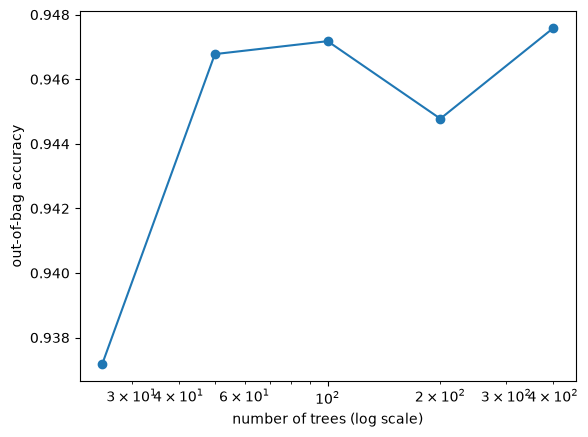

,trees,out-of-bag accuracy
0,25,0.937
1,50,0.947
2,100,0.947
3,200,0.945
4,400,0.948


In [10]:
rows = []
for n_trees in [25, 50, 100, 200, 400]:
    rf = RandomForestClassifier(n_estimators=n_trees, oob_score=True, random_state=0, n_jobs=-1).fit(X_train, y_train)
    rows.append({"trees": n_trees, "out-of-bag accuracy": rf.oob_score_})
oob = pd.DataFrame(rows)

plt.plot(oob["trees"], oob["out-of-bag accuracy"], marker="o")
plt.xscale("log")
plt.xlabel("number of trees (log scale)")
plt.ylabel("out-of-bag accuracy")
plt.show()
oob.round(3)

The out-of-bag accuracy climbs from 0.937 with 25 trees and levels off at about 0.95 from 50 trees onwards. Adding trees never makes a forest overfit; it only costs time. Note that the out-of-bag score uses accuracy, the default for classifiers, which is why it looks high on this imbalanced data.

### A forest is more stable than a tree

The same ten resamples as in section 2, now with a forest instead of a single tree:

Tree:   mean F1 0.735, standard deviation 0.028
Forest: mean F1 0.862, standard deviation 0.017


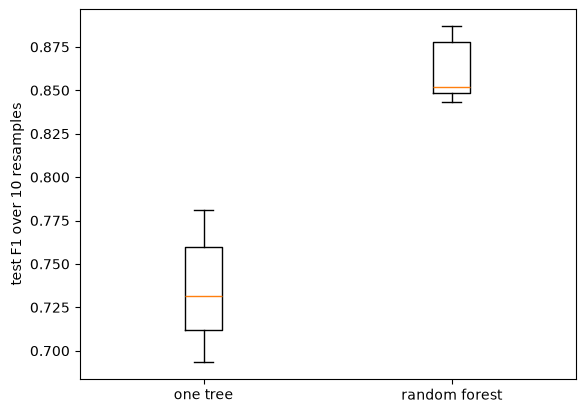

In [11]:
forest_f1 = []
for idx in resamples:
    rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1).fit(X_train.iloc[idx], y_train.iloc[idx])
    forest_f1.append(f1_score(y_test, rf.predict(X_test)))

print(f"Tree:   mean F1 {np.mean(tree_f1):.3f}, standard deviation {np.std(tree_f1):.3f}")
print(f"Forest: mean F1 {np.mean(forest_f1):.3f}, standard deviation {np.std(forest_f1):.3f}")

plt.boxplot([tree_f1, forest_f1], tick_labels=["one tree", "random forest"])
plt.ylabel("test F1 over 10 resamples")
plt.show()

The forest is better on average (F1 0.862 against 0.735) and its scores vary much less from one training sample to the next: the standard deviation drops from 0.028 to 0.017. That is the variance reduction that bagging promised.

## 5. Feature importance

A forest of 300 trees cannot be drawn and read like the single tree on Week 4 Day 5. What we can still ask is **which features the model relies on**. There are two common answers.

### Impurity-based importance

Every fitted forest has `feature_importances_`: how much each feature reduced impurity (Gini or entropy), summed over all the splits that use it and averaged over the trees. The values add up to 1.

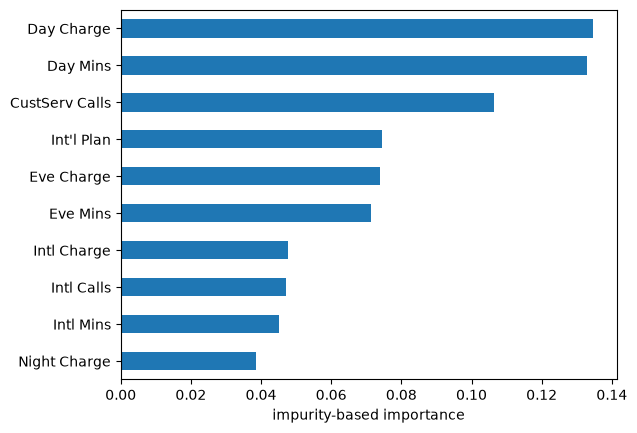

Day Charge        0.135
Day Mins          0.133
CustServ Calls    0.106
Int'l Plan        0.074
Eve Charge        0.074
Eve Mins          0.071
dtype: float64

In [12]:
impurity_imp = pd.Series(forest.feature_importances_, index=X.columns).sort_values()
impurity_imp.tail(10).plot.barh()
plt.xlabel("impurity-based importance")
plt.show()
impurity_imp.sort_values(ascending=False).head(6).round(3)

Daytime usage (`Day Charge` and `Day Mins`) comes first, then customer service calls and the international plan, the same kind of usage and service features that drove last week's single tree.

### Permutation importance

**Permutation importance** asks a more direct question: if this column were shuffled, so that it carried no information, how much worse would the model score? It works for any model, and computed on the test set it measures what matters for new data rather than for the training set.

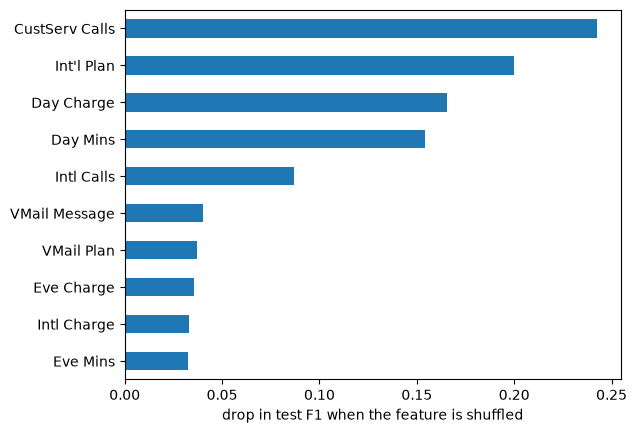

CustServ Calls    0.243
Int'l Plan        0.200
Day Charge        0.165
Day Mins          0.154
Intl Calls        0.087
VMail Message     0.040
dtype: float64

In [13]:
perm = permutation_importance(forest, X_test, y_test, scoring="f1", n_repeats=10, random_state=0, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
perm_imp.tail(10).plot.barh()
plt.xlabel("drop in test F1 when the feature is shuffled")
plt.show()
perm_imp.sort_values(ascending=False).head(6).round(3)

The order changes: shuffling `CustServ Calls` costs the most F1 (0.24), followed by the international plan (0.20), and daytime usage comes third and fourth. The impurity ranking spread its credit over every split in every tree, many of them deep splits on a handful of training rows; the permutation ranking measures what actually helps on unseen customers.

Three cautions apply to both methods:

+ **Correlated features share the credit.** `Day Charge` is the price of `Day Mins`, so they carry the same information. Drop one and the other's importance roughly doubles; neither ranking is wrong, they just cannot tell the pair apart.
+ **Impurity importance favours features with many distinct values**, such as continuous ones, and is computed on the training data. Prefer permutation importance when the two disagree.
+ **Importance is not causation.** Customers who call customer service often are more likely to leave, but the calls are probably a symptom of a problem, not its cause.

## 6. Boosting

Bagging trains its models **in parallel**, each on its own sample. Boosting trains them **in sequence**: each new model focuses on what the ensemble so far gets wrong. The individual models are usually small, *weak learners* such as shallow trees, and the ensemble becomes strong by adding them up.

Bagging mainly reduces variance; boosting mainly reduces **bias**, which is also why it can overfit if you let it run too long.

### AdaBoost

**AdaBoost** (*adaptive boosting*), the first popular boosting method, keeps a weight for every training row. After each model, the rows it misclassified get a larger weight, so the next model concentrates on them. The final prediction is a weighted vote, in which more accurate models get a bigger say.

Its default weak learner is a **stump**, a tree with a single split. On churn, how strong the weak learner is matters a lot:

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for depth in [1, 2, 3]:
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=depth), n_estimators=200, random_state=0)
    scores = cross_val_score(ada, X_train, y_train, cv=cv, scoring="f1")
    print(f"AdaBoost, 200 trees of depth {depth}: cross-validated F1 {scores.mean():.3f}")

AdaBoost, 200 trees of depth 1: cross-validated F1 0.381


AdaBoost, 200 trees of depth 2: cross-validated F1 0.653


AdaBoost, 200 trees of depth 3: cross-validated F1 0.752


With stumps AdaBoost reaches an F1 of only 0.381, far below a single tree. With trees of depth 3 it reaches 0.752, as good as yesterday's tuned tree. A stump asks one question; churn depends on combinations of features (heavy daytime use *and* no voicemail), and a sum of single questions cannot express an "and" well.

### Gradient boosting

**Gradient boosting** builds the ensemble differently. It starts from a simple prediction, then each new tree is trained to predict the **errors (residuals)** of the ensemble so far, and its prediction is added, scaled down by a **learning rate**. Step by step, the ensemble's errors shrink.

It is easiest to see on a regression problem with one feature. Here each step adds a tree of depth 2 fitted to the current residuals:

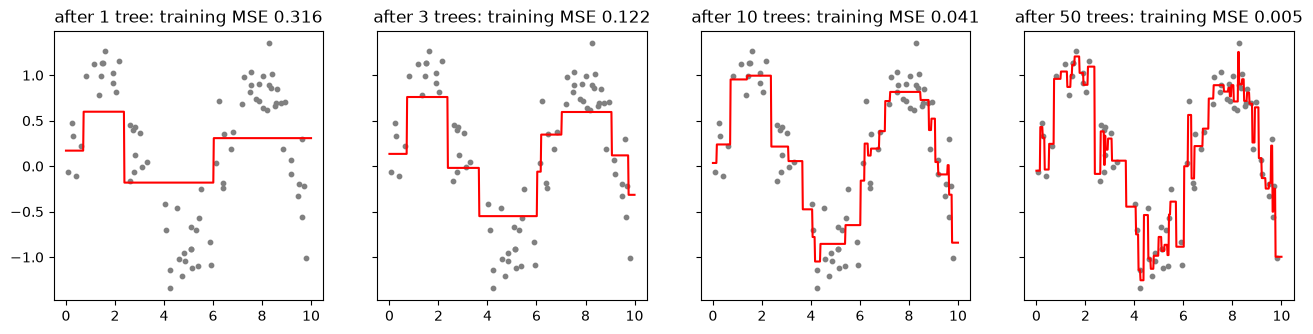

In [15]:
rng = np.random.default_rng(1)
x_1d = np.sort(rng.uniform(0, 10, 80)).reshape(-1, 1)
y_1d = np.sin(x_1d).ravel() + rng.normal(0, 0.3, 80)
x_plot = np.linspace(0, 10, 500).reshape(-1, 1)

learning_rate = 0.5
prediction = np.full(len(y_1d), y_1d.mean())
curve = np.full(len(x_plot), y_1d.mean())
snapshots = {}
for step in range(1, 51):
    residuals = y_1d - prediction
    small_tree = DecisionTreeRegressor(max_depth=2).fit(x_1d, residuals)
    prediction += learning_rate * small_tree.predict(x_1d)
    curve += learning_rate * small_tree.predict(x_plot)
    if step in (1, 3, 10, 50):
        snapshots[step] = (curve.copy(), np.mean((y_1d - prediction) ** 2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (step, (c, mse)) in zip(axes, snapshots.items()):
    ax.scatter(x_1d, y_1d, s=10, color="grey")
    ax.plot(x_plot, c, color="red")
    ax.set_title(f"after {step} tree{'s' if step > 1 else ''}: training MSE {mse:.3f}")
plt.show()

After one small tree the prediction is a crude step; after ten it follows the sine wave; after fifty it is starting to chase individual noisy points. That last part is how boosting overfits: given enough trees, it fits the noise too.

`GradientBoostingClassifier` applies the same idea to classification, fitting each tree to the errors of the predicted probabilities. Its key settings work as a pair:

+ `n_estimators`: how many trees to add.
+ `learning_rate`: how much of each tree's prediction to add. A smaller rate needs more trees but usually generalises better.
+ `max_depth`: the size of each tree, 3 by default.

To choose them honestly, we hold out a **validation set from the training data** and watch the validation error as trees are added. `staged_predict_proba` returns the predicted probabilities after 1, 2, 3, ... trees without retraining. We track **log loss**, the error that gradient boosting minimises for classification: it punishes confident wrong probabilities, and lower is better. The test set stays untouched.

learning_rate=0.01: lowest validation log loss 0.191 after 498 trees, 0.191 after 500


learning_rate=0.1 : lowest validation log loss 0.178 after 219 trees, 0.187 after 500


learning_rate=1.0 : lowest validation log loss 0.242 after 5 trees, 0.642 after 500


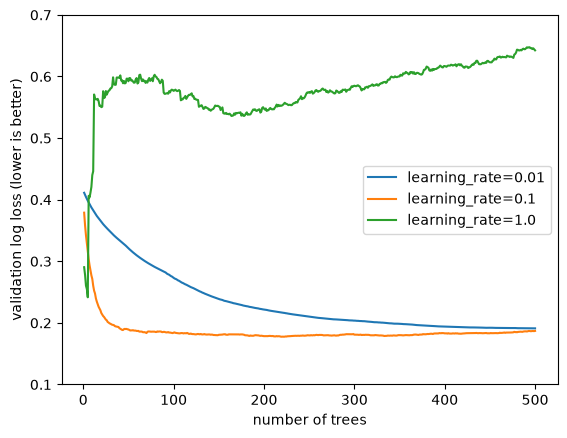

In [16]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=0)

for lr in [0.01, 0.1, 1.0]:
    gb = GradientBoostingClassifier(learning_rate=lr, n_estimators=500, random_state=0).fit(X_fit, y_fit)
    val_loss = [log_loss(y_val, p) for p in gb.staged_predict_proba(X_val)]
    plt.plot(range(1, 501), val_loss, label=f"learning_rate={lr}")
    print(f"learning_rate={lr:<4}: lowest validation log loss {min(val_loss):.3f} after {np.argmin(val_loss) + 1} trees, "
          f"{val_loss[-1]:.3f} after 500")
plt.xlabel("number of trees")
plt.ylabel("validation log loss (lower is better)")
plt.ylim(0.1, 0.7)
plt.legend()
plt.show()

+ With **learning rate 1.0**, each tree's full prediction is added. The validation loss is lowest after 5 trees, then jumps up and keeps drifting higher: the model overfits within a handful of trees.
+ With **0.1**, the default, it reaches the lowest loss of the three (0.178) after about 220 trees and stays flat after that.
+ With **0.01**, it is still improving after 500 trees; it would need thousands to catch up.

Smaller steps need more trees, but they generalise better. A common recipe is to fix a small learning rate and let early stopping, or a validation curve like this one, choose the number of trees.

### HistGradientBoosting: the one to use in practice

`HistGradientBoostingClassifier` is scikit-learn's modern implementation of gradient boosting, inspired by LightGBM. It first groups each feature's values into at most 255 bins, which makes training much faster on large data. It also:

+ **handles missing values natively**, with no imputer needed;
+ can treat columns as categorical (`categorical_features="from_dtype"` with pandas `category` columns);
+ **stops early by itself**: on datasets over 10,000 rows, or with `early_stopping=True`, it holds out a validation part of the training data and stops adding trees once the score stops improving.

In [17]:
hgb = HistGradientBoostingClassifier(random_state=0).fit(X_train, y_train)
gboost = GradientBoostingClassifier(random_state=0).fit(X_train, y_train)
report("Gradient boosting", gboost)
report("HistGradientBoosting", hgb)

hgb_early = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=0).fit(X_train, y_train)
print("\nWith early stopping, it stopped after", hgb_early.n_iter_, "of at most 1000 trees")
report("HistGB, early stopping", hgb_early)

Gradient boosting          accuracy 0.966   F1 0.878   recall 0.835   precision 0.927
HistGradientBoosting       accuracy 0.970   F1 0.892   recall 0.851   precision 0.936



With early stopping, it stopped after 45 of at most 1000 trees
HistGB, early stopping     accuracy 0.964   F1 0.870   recall 0.826   precision 0.917


On churn both implementations are excellent, with HistGradientBoosting slightly ahead (F1 0.892, finding 85% of the churners with 94% precision). With early stopping it needed only 45 trees, at the cost of a slightly lower score on this small dataset, because it gives up part of the training data to validate on.

XGBoost, LightGBM and CatBoost are separate libraries built on the same idea, with the same `fit` / `predict` interface. You will meet them in competitions; `HistGradientBoosting` covers what you need without installing anything.

## 7. Comparing everything on churn

The same rules as yesterday: compare the candidates with cross-validation on the training set, choose one, and only then look at the test set, once. The first two rows are the trees from Week 4 Day 5 and from yesterday.

In [18]:
candidates = {
    "Tree, depth 5 (Week 4 Day 5)": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Tree, tuned (Day 1)": DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=0),
    "Bagging": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0, n_jobs=-1),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "AdaBoost, depth 3": AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=200, random_state=0),
    "Gradient boosting": GradientBoostingClassifier(random_state=0),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=0),
}
rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["f1", "recall", "precision"])
    rows.append({"model": name,
                 "CV F1": scores["test_f1"].mean(),
                 "CV F1 std": scores["test_f1"].std(),
                 "CV recall": scores["test_recall"].mean(),
                 "CV precision": scores["test_precision"].mean()})
comparison = pd.DataFrame(rows).set_index("model").sort_values("CV F1", ascending=False)
comparison.round(3)

,CV F1,CV F1 std,CV recall,CV precision
model,,,,
HistGradientBoosting,0.795,0.019,0.691,0.937
Bagging,0.789,0.018,0.688,0.929
Gradient boosting,0.788,0.022,0.702,0.903
Random forest,0.787,0.018,0.694,0.916
"AdaBoost, depth 3",0.752,0.017,0.666,0.865
"Tree, tuned (Day 1)",0.739,0.034,0.657,0.849
"Tree, depth 5 (Week 4 Day 5)",0.735,0.023,0.666,0.828


+ **Every ensemble beats the single trees**, by about 0.05 in F1, and the gain comes mostly from precision: fewer loyal customers wrongly flagged.
+ The four leaders are within 0.01 of each other, less than the variation from fold to fold (the `CV F1 std` column). Any of them is a sound choice; HistGradientBoosting is on top, so we take it.
+ All of them use **default settings**. Tuning, with the grid search from yesterday, would add a little more, mostly for the boosting models.

Only now, the test set, once, for the model we chose:

In [19]:
best_name = comparison.index[0]
best_model = candidates[best_name].fit(X_train, y_train)
report(best_name, best_model)

HistGradientBoosting       accuracy 0.970   F1 0.892   recall 0.851   precision 0.936


Test F1 0.892, against 0.851 for the depth-5 tree of Week 4 Day 5 and 0.853 for yesterday's tuned tree. Of the 121 churners in the test set, the model finds 103, and 94% of the customers it flags really leave.

The test score is higher than the cross-validated one (0.795). That happens with a single test set of 121 churners; the cross-validated score is the more reliable estimate of how the model will do on new customers.

## Summary

| | Bagging and random forests | Boosting |
|---|---|---|
| How the models are trained | in parallel, each on a bootstrap sample | in sequence, each fixing the previous ones' errors |
| Typical base model | deep trees (low bias, high variance) | shallow trees (weak learners) |
| What it mainly reduces | variance | bias |
| Can it overfit by adding models? | no, more trees only cost time | yes, so tune `n_estimators` with `learning_rate`, or use early stopping |
| Settings that matter most | `n_estimators`, `max_features` | `learning_rate`, `n_estimators`, `max_depth` |
| Needs scaled features? | no | no |
| Good default | `RandomForestClassifier(n_estimators=300, n_jobs=-1)` | `HistGradientBoostingClassifier()` |

+ An ensemble only helps if its models make **different mistakes**.
+ **Feature importance**: prefer permutation importance on the test set, and remember that correlated features share credit.
+ On tabular data, a **tuned gradient boosting model is the usual winner**; a random forest is a strong baseline that needs almost no tuning.
+ Choose between models with **cross-validation**; look at the test set once.

## Appendix

### A.1 Ensembles for regression

Every ensemble has a regression version: `BaggingRegressor`, `RandomForestRegressor`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor`. They average numbers instead of counting votes. On the diabetes dataset built into scikit-learn (disease progression after one year, from ten measurements):

In [20]:
X_d, y_d = load_diabetes(return_X_y=True)
regressors = {
    "Linear regression": LinearRegression(),
    "Tree": DecisionTreeRegressor(random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=0),
}
for name, model in regressors.items():
    r2 = cross_val_score(model, X_d, y_d, cv=5, scoring="r2").mean()
    print(f"{name:<22} cross-validated R² {r2:.3f}")

Linear regression      cross-validated R² 0.482
Tree                   cross-validated R² -0.096


Random forest          cross-validated R² 0.425


HistGradientBoosting   cross-validated R² 0.375


A single tree is far worse than linear regression here, and the ensembles close most of the gap, but they do not win: with 442 rows and a relationship that is close to linear, a linear model is hard to beat. Ensembles shine when the data is larger and the relationships are non-linear, as on churn.

### A.2 Voting and stacking

Ensembles can also combine **different algorithms**.

+ `VotingClassifier` averages their votes, or with `voting="soft"` their predicted probabilities.
+ `StackingClassifier` trains a final model, by default a logistic regression, that learns how much to trust each one, using cross-validated predictions so it does not learn from leaked answers.

In [21]:
base_models = [
    ("forest", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)),
    ("hgb", HistGradientBoostingClassifier(random_state=0)),
    ("logreg", make_pipeline(StandardScaler(), LogisticRegression())),
]
for name, model in [("Soft voting", VotingClassifier(base_models, voting="soft")),
                    ("Stacking", StackingClassifier(base_models))]:
    print(f"{name:<12} cross-validated F1 {cross_val_score(model, X_train, y_train, cv=cv, scoring='f1').mean():.3f}")

Soft voting  cross-validated F1 0.777


Stacking     cross-validated F1 0.802


Stacking (0.802) edges past HistGradientBoosting alone (0.795), while soft voting (0.777) does worse, because the weaker logistic regression drags the average down. Stacking learns to give it little weight. The gain is small for three times the training cost, which is typical: these methods win competitions by fractions of a point but are rarely worth the complexity in production.

### A.3 Multiclass problems and error-correcting output codes

Some models handle many classes naturally: a tree stores the class in its leaves, KNN looks at its neighbours' labels. Others are binary at heart, such as an SVM, which separates two classes with one boundary. There are three standard ways to turn binary classifiers into a multiclass one:

+ **One-vs-rest**: one classifier per class, "this class against all the others"; predict the class whose classifier is most confident. *k* classifiers for *k* classes.
+ **One-vs-one**: one classifier per pair of classes; predict the class that wins most duels. *k(k−1)/2* classifiers.
+ **Error-correcting output codes (ECOC)**: give each class a binary code word, for example class 3 = `1 0 1 1 0`. Train one classifier per bit, each on its own grouping of the classes. To predict, compute the code word and pick the class whose code is closest. With longer codes, a few classifiers can be wrong and the answer is still right, like an error-correcting code in telecommunications.

scikit-learn applies these automatically (`LogisticRegression` and `SVC` are multiclass out of the box), but the wrappers let you choose. On the handwritten digits (10 classes), with a linear model at each step:

In [22]:
X_dig, y_dig = load_digits(return_X_y=True)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
wrappers = {
    "One-vs-rest (10 models)": OneVsRestClassifier(base),
    "One-vs-one (45 models)": OneVsOneClassifier(base),
    "ECOC, code size 1.5 (15 models)": OutputCodeClassifier(base, code_size=1.5, random_state=0),
}
for name, model in wrappers.items():
    print(f"{name:<32} cross-validated accuracy {cross_val_score(model, X_dig, y_dig, cv=5).mean():.3f}")

One-vs-rest (10 models)          cross-validated accuracy 0.923


One-vs-one (45 models)           cross-validated accuracy 0.948


ECOC, code size 1.5 (15 models)  cross-validated accuracy 0.874


With 15 classifiers, fewer than one-vs-one's 45, ECOC is the least accurate here; longer codes (a larger `code_size`) buy back accuracy at the cost of more models. One-vs-one wins on digits because each of its models only has to separate two digits, which is easy for a straight line.

### A.4 Bagging by hand

To check there is no magic in `BaggingClassifier`: draw bootstrap samples, train a tree on each, and take the majority vote.

In [23]:
rng = np.random.default_rng(0)
votes = np.zeros(len(X_test))
n_trees = 100
for _ in range(n_trees):
    idx = rng.integers(0, len(X_train), len(X_train))
    tree_i = DecisionTreeClassifier().fit(X_train.iloc[idx], y_train.iloc[idx])
    votes += tree_i.predict(X_test)

y_pred_hand = (votes / n_trees > 0.5).astype(int)
print(f"Bagging by hand: F1 {f1_score(y_test, y_pred_hand):.3f}")
report("BaggingClassifier", bagging)

Bagging by hand: F1 0.856
BaggingClassifier          accuracy 0.962   F1 0.858   recall 0.802   precision 0.924


The two scores are close but not identical: the random samples differ, and `BaggingClassifier` averages the trees' probabilities rather than counting their votes.